# MLPSymbol frente a ParabolicMLPSymbol
Se entrenan y comparan `MLPSymbol` (MLP con salida lineal, acotada) y `ParabolicMLPSymbol` sobre el calor en $\mathbb{T}^2$ ($a(\mathbf{k})=|\mathbf{k}|^2$, $m=2$).
Reparametrizacion: $a_\theta(\mathbf{k})=\langle\mathbf{k}\rangle^m\big(c+(C-c)\,\sigma(g_\theta(\mathbf{k}/\langle\mathbf{k}\rangle))\big)$ para $\mathbf{k}\neq0$, y $a_\theta(0)=0$.
Secciones: **0.** Datos · **1.** Entrenamiento · **2.** Comparacion de los modelos entrenados.

In [1]:
import sys
sys.path.insert(0, "../src")  # ruta para las clases

import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from parabolic_symbol.symbols.heat import HeatSymbol
from parabolic_symbol.symbols.mlp_symbol import MLPSymbol, default_device
from parabolic_symbol.symbols.parabolic_mlp_symbol import ParabolicMLPSymbol
from parabolic_symbol.data import make_trajectory_data, phase_grid, split_trajectory_data
from parabolic_symbol.estimation import estimate_bounds, estimate_symbol
from parabolic_symbol.evaluation import symbol_report, trajectory_report
from parabolic_symbol.losses import parabolicity_terms
from parabolic_symbol.sweep import max_ratio_on
from parabolic_symbol.training import TrainingConfig, train

np.set_printoptions(precision=4, suppress=True)

device = default_device()
# Doble precision siempre: la comparacion llega a <k>^m ~ 10^6.
dtype = torch.float64
print(f"device = {device}  |  dtype = {dtype}")

device = cpu  |  dtype = torch.float64


## 0. Datos

Los mismos del notebook original: $10^5$ muestras con $|k_i|\le 12$ y particion **por $\mathbf{k}$** 80/20, asi que los $\mathbf{k}$ de validacion nunca se ven al entrenar.

In [2]:
n = 2
m = 2.0
k_max = 12
omega = 1.0
reference = HeatSymbol(n=n)

data = make_trajectory_data(
    reference, k_max=k_max, n_samples=100000, t_min=1e-3, t_max=1.0, seed=0
)
train_data, val_data = split_trajectory_data(data, val_fraction=0.2, seed=0)

k_train_values = np.unique(train_data["k"].numpy(), axis=0)
k_val_values = np.unique(val_data["k"].numpy(), axis=0)
print(f"entrenamiento: {train_data['k'].shape[0]:,} muestras / {len(k_train_values)} k unicos")
print(f"validacion:    {val_data['k'].shape[0]:,} muestras / {len(k_val_values)} k unicos")

entrenamiento: 79,836 muestras / 500 k unicos
validacion:    20,164 muestras / 125 k unicos


## 1. Entrenamiento

La banda $(c, C)$ se estima solo con los datos de entrenamiento ($\delta=0.1$) y fija el $\kappa$ teorico de `ParabolicMLPSymbol`.

In [3]:
k_est, a_hat = estimate_symbol(train_data, tol=1e-10, verbose=False)
bounds_data = estimate_bounds(k_est, a_hat, m, delta=0.1)
c_data, C_data_band = bounds_data.c, bounds_data.C
hidden = (64, 64, 64)

parabolic = ParabolicMLPSymbol(n=n, m=m, c=c_data, C=C_data_band, hidden=hidden,
                               seed=0, device=device, dtype=dtype)
kappa_theo = parabolic.theoretical_kappa(omega)
print(f"c = {c_data:.4f}  |  C = {C_data_band:.4f}  |  kappa teorico = {kappa_theo:.4f}")

c = 0.4500  |  C = 1.0962  |  kappa teorico = 3.1427


Ambos modelos usan la misma arquitectura ($3\times64$, `Tanh`), el mismo presupuesto y el mismo $\kappa$ teorico en $\mathcal{L}_{\text{par}}$, para que el ratio de parabolicidad sea comparable.

In [4]:
base_config = TrainingConfig(
    epochs=150,
    batch_size=1024,
    lr=1e-3,
    lr_final=1e-5,
    omega=omega,
    kappa=kappa_theo,
    lambda_trajectory=1.0,
    lambda_parabolicity=1.0,
    lambda_class=1.0,
    class_C_source="data",   # C_alpha por diferencias finitas de a_hat
    k_max=k_max,
    lam_min=1e-2,
    lam_max=1e2,
    grad_clip=1.0,
    patience=30,
    n_phase_eval=8192,
    log_every=25,
    seed=0,
)

t0 = time.perf_counter()
result_parabolic = train(parabolic, train_data, val_data, base_config)
time_parabolic = time.perf_counter() - t0
print(f"ParabolicMLPSymbol: {time_parabolic:.0f}s\n")

mlp = MLPSymbol(n=n, m=m, hidden=hidden, input_scale=k_max, output_scale=k_max**2,
                seed=0, device=device, dtype=dtype)
t0 = time.perf_counter()
result_mlp = train(mlp, train_data, val_data, base_config)
time_mlp = time.perf_counter() - t0
print(f"MLPSymbol: {time_mlp:.0f}s")

hidden=(64, 64, 64) | dropout OFF | weight_decay=0 en 2 Linear interiores
epoca   25 | val: total=2.453e-06 traj=2.453e-06 par=0.000e+00 class=0.000e+00 rel_l2=0.0034 max_ratio=0.709 viol= 0.00%
epoca   50 | val: total=1.489e-06 traj=1.489e-06 par=0.000e+00 class=0.000e+00 rel_l2=0.0027 max_ratio=0.710 viol= 0.00%
epoca   75 | val: total=1.944e-06 traj=1.944e-06 par=0.000e+00 class=0.000e+00 rel_l2=0.0031 max_ratio=0.709 viol= 0.00%
epoca  100 | val: total=1.461e-06 traj=1.461e-06 par=0.000e+00 class=0.000e+00 rel_l2=0.0026 max_ratio=0.710 viol= 0.00%
early stopping en la epoca 113 (mejor: 83)
ParabolicMLPSymbol: 301s

hidden=(64, 64, 64) | dropout OFF | weight_decay=0 en 2 Linear interiores
epoca   25 | val: total=2.382e+02 traj=2.382e+02 par=8.280e-02 class=8.816e-03 rel_l2=33.8029 max_ratio=31.817 viol= 2.08%
epoca   50 | val: total=2.171e-03 traj=2.171e-03 par=0.000e+00 class=3.293e-04 rel_l2=0.1021 max_ratio=0.709 viol= 0.00%
epoca   75 | val: total=1.338e-03 traj=1.338e-03 par=0.

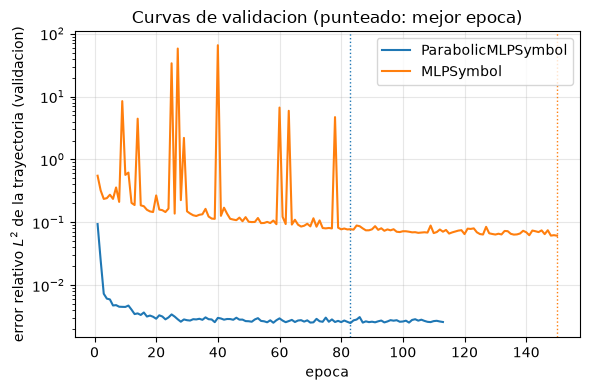

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
for nombre, res, color in (("ParabolicMLPSymbol", result_parabolic, "C0"), ("MLPSymbol", result_mlp, "C1")):
    h = res.history["val"]["rel_l2"]
    ax.semilogy(np.arange(1, len(h) + 1), h, color=color, label=nombre)
    ax.axvline(res.best_epoch, color=color, ls=":", lw=1)
ax.set_xlabel("epoca")
ax.set_ylabel(r"error relativo $L^2$ de la trayectoria (validacion)")
ax.set_title("Curvas de validacion (punteado: mejor epoca)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 2. Comparacion

### 2.1 Trayectoria y simbolo en los $\mathbf{k}$ de validacion
Errores sobre los $\mathbf{k}$ que ningun modelo vio, y $\mathcal{L}_{\text{par}}$, $\mathcal{L}_{\text{class}}$ en la mejor epoca.

In [6]:
models = {"ParabolicMLPSymbol": (parabolic, result_parabolic),
          "MLPSymbol": (mlp, result_mlp)}

filas = {}
for nombre, (sym, res) in models.items():
    traj_val = trajectory_report(sym, val_data)
    sym_val = symbol_report(sym, reference, k_val_values)
    e = res.best_epoch - 1
    filas[nombre] = {
        "traj val rel_l2": traj_val["rel_l2"],
        "traj val rmse": traj_val["rmse"],
        "traj val r2": traj_val["r2"],
        "simbolo val rel_l2": sym_val["rel_l2"],
        "simbolo val max_error": sym_val["max_error"],
        "L_par val (mejor epoca)": res.history["val"]["parabolicity"][e],
        "L_class val (mejor epoca)": res.history["val"]["class"][e],
        "mejor epoca": res.best_epoch,
        "epocas": len(res.history["val"]["total"]),
    }
display(pd.DataFrame(filas))

,ParabolicMLPSymbol,MLPSymbol
traj val rel_l2,0.002501,0.061301
traj val rmse,0.001142,0.027986
traj val r2,0.999994,0.996242
simbolo val rel_l2,0.004391,0.193472
simbolo val max_error,1.612112,90.165270
L_par val (mejor epoca),0.000000,0.000000
L_class val (mejor epoca),0.000000,0.000054
mejor epoca,83.000000,150.000000
epocas,113.000000,150.000000


### 2.2 Parabolicidad en la rejilla de certificacion
Peor ratio con $|\lambda|\in[10^{-2},10^3]$ y ventanas $|k_i|\le K$ hasta $3k_{\max}=36$, dentro y fuera de la ventana de entrenamiento.

In [7]:
cert_radii = np.logspace(-2, 3, 25)
cert_angles = np.linspace(-np.pi / 2, np.pi / 2, 25)
cert_lam = (cert_radii[:, None] * np.exp(1j * cert_angles)).ravel()
cert_k_max = 3 * k_max


def cert_metrics(sym, k_window, kappa, chunk=200_000):
    # Peor ratio y L_par sobre (|k_i| <= k_window) x cert_lam, por trozos.
    kk, ll = phase_grid(n, k_window, cert_lam, device=device, dtype=dtype)
    worst, sq_sum, count = 0.0, 0.0, 0
    with torch.no_grad():
        for i in range(0, kk.shape[0], chunk):
            violation, ratio = parabolicity_terms(sym, kk[i : i + chunk], ll[i : i + chunk], omega, kappa)
            worst = max(worst, float(ratio.max()))
            sq_sum += float(torch.sum(violation**2))
            count += violation.numel()
    return worst, sq_sum / count


filas = []
for nombre, (sym, _) in models.items():
    for window in (k_max, 2 * k_max, cert_k_max):
        worst, l_par = cert_metrics(sym, window, kappa_theo)
        filas.append({"modelo": nombre, "|k_i| <=": window,
                      "ventana": "dentro" if window <= k_max else "fuera",
                      "max ratio": worst, "L_par": l_par,
                      "kappa_hat minimo": kappa_theo * worst, "cumple": worst <= 1.0})
display(pd.DataFrame(filas))

,modelo,|k_i| <=,ventana,max ratio,L_par,kappa_hat minimo,cumple
0,ParabolicMLPSymbol,12,dentro,0.720867,0.000000e+00,2.265467,True
1,ParabolicMLPSymbol,24,fuera,0.720867,0.000000e+00,2.265467,True
2,ParabolicMLPSymbol,36,fuera,0.720867,0.000000e+00,2.265467,True
3,MLPSymbol,12,dentro,0.708209,0.000000e+00,2.225685,True
4,MLPSymbol,24,fuera,1.329444,2.062594e-09,4.178040,False
5,MLPSymbol,36,fuera,2.834316,2.135829e-07,8.907396,False


### 2.3 Lejos de la ventana: $|\mathbf{k}|$ hasta $10^3$
Simbolo aprendido y peor ratio a lo largo del eje $(K,0)$ y la diagonal $(K,K)$, para ver que pasa donde no hubo datos.

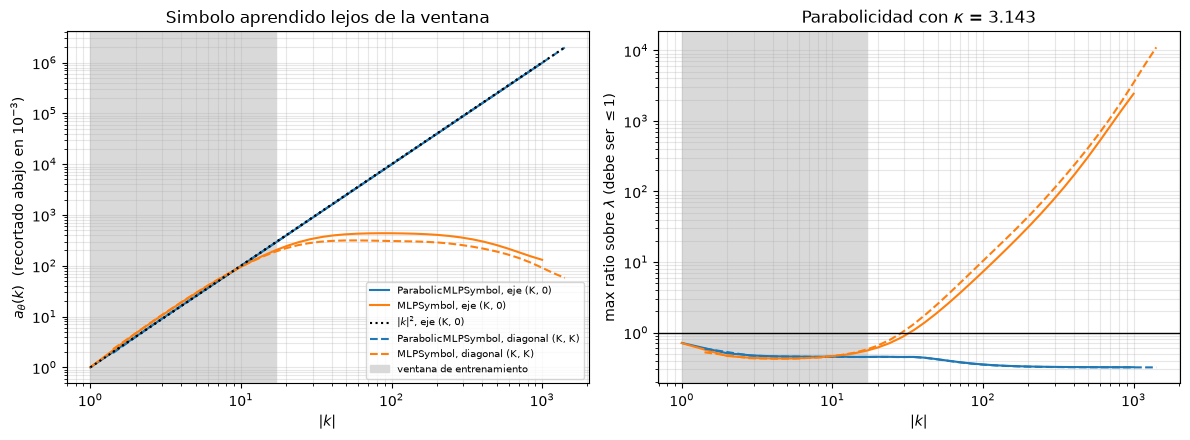

,modelo,perfil,max ratio (|k| <= 17),"max ratio (todo, |k|_inf <= 1000)",a_theta(1000 en el perfil),exacto
0,ParabolicMLPSymbol,"eje (K, 0)",0.712918,0.712918,9.865931e+05,1000000.0
1,ParabolicMLPSymbol,"diagonal (K, K)",0.592615,0.592615,1.983487e+06,2000000.0
2,MLPSymbol,"eje (K, 0)",0.708209,2427.941322,1.310569e+02,1000000.0
3,MLPSymbol,"diagonal (K, K)",0.577651,11037.775690,5.765622e+01,2000000.0


In [8]:
K_prof = np.unique(np.round(np.logspace(0, 3, 40))).astype(float)
profiles = {"eje (K, 0)": np.stack([K_prof, 0 * K_prof], 1),
            "diagonal (K, K)": np.stack([K_prof, K_prof], 1)}


def ratio_profile(sym, ks):
    out = []
    for k in ks:
        kk = torch.tensor(np.repeat(k[None], len(cert_lam), 0), dtype=dtype)
        ll = torch.tensor(cert_lam, dtype=torch.complex128)
        out.append(max_ratio_on(sym, (kk, ll), omega, kappa_theo))
    return np.array(out)


fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for nombre_p, ks in profiles.items():
    norm_p = np.linalg.norm(ks, axis=1)
    ls = "-" if nombre_p.startswith("eje") else "--"
    for nombre, (sym, _), color in zip(models, models.values(), ("C0", "C1")):
        axes[0].loglog(norm_p, np.maximum(np.real(sym.evaluate_batch(ks)), 1e-3), ls, color=color,
                       label=f"{nombre}, {nombre_p}")
        axes[1].loglog(norm_p, ratio_profile(sym, ks), ls, color=color, label=f"{nombre}, {nombre_p}")
    axes[0].loglog(norm_p, norm_p**2, ":", color="k", lw=1.5, label=rf"$|k|^2$, {nombre_p}" if ls == "-" else None)
for ax in axes:
    ax.axvspan(1, np.sqrt(2) * k_max, color="0.85", zorder=0, label="ventana de entrenamiento")
    ax.set_xlabel(r"$|k|$")
    ax.grid(alpha=0.3, which="both")
axes[0].set_ylabel(r"$a_\theta(k)$  (recortado abajo en $10^{-3}$)")
axes[0].set_title("Simbolo aprendido lejos de la ventana")
axes[1].axhline(1.0, color="k", lw=1)
axes[1].set_ylabel(r"max ratio sobre $\lambda$ (debe ser $\leq 1$)")
axes[1].set_title(rf"Parabolicidad con $\kappa$ = {kappa_theo:.3f}")
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

filas = []
for nombre, (sym, _) in models.items():
    for nombre_p, ks in profiles.items():
        r = ratio_profile(sym, ks)
        filas.append({"modelo": nombre, "perfil": nombre_p, "max ratio (|k| <= 17)":
                      r[np.linalg.norm(ks, axis=1) <= np.sqrt(2) * k_max].max(),
                      "max ratio (todo, |k|_inf <= 1000)": r.max(),
                      "a_theta(1000 en el perfil)": float(np.real(sym.evaluate_batch(ks[-1:])[0])),
                      "exacto": float(np.sum(ks[-1] ** 2))})
display(pd.DataFrame(filas))